In [169]:
import os
import sys
import clr
import pandas as pd


# ==========================================================
# 1. CONFIGURACIÓN DE LA CONSULTA
# ==========================================================

TAGS = [

    # ======================================================
    # BALANCE DE VAPOR
    # ======================================================

    # Vapor MS importado desde límite de batería
    "FCCFI30303BM.DACA.PV",

    # Vapor MS exportado desde FCC
    "FCCFI30303AM.DACA.PV",

    # Vapor MS generado dentro de FCC
    "FCCFI12901M.DACA.PV",

    # Consumo de vapor compresor de gases
    "RG1FI00303.DACA.PV",


    # ======================================================
    # BOMBAS DE FONDOS P-017A / P-017B
    # ======================================================

    # Velocidad bomba de fondos P-017A
    "FCCSI80810A.DACA.PV",

    # Velocidad bomba de fondos P-017B
    "FCCSI80810B.DACA.PV",


    # ======================================================
    # CONDENSADOR / VACÍO
    # ======================================================

    # Presión absoluta del condensador
    "FCCPI13162M.PV",

    # Flujo de agua de mar
    "FCCFI30202.DACA.PV",

    # Temperatura entrada agua de mar
    "FCCTI30204.DACA.PV",

    # Temperatura salida agua de mar
    "FCCTI30208.DACA.PV",

    # Presión entrada agua de mar
    "FCCPI30204.DACA.PV",


    # ======================================================
    # SOPLADOR / TURBINA
    # ======================================================

    # Flujo de aire del soplador
    "FCCFI10561M.DACA.PV",

    # Temperatura descarga soplador
    "FCCTI10464.PV",

    # Presión descarga soplador
    "FCCPI10463.PV",

    # RPM turbina
    "FCCSI70129B.PV",

    # Presión vapor entrada turbina
    "FCCPI10405M.PV",

    # Temperatura vapor entrada turbina
    "FCCTI10401M.PV",

    # Apertura antisurge
    "FCCZI10461.PV",


    # ======================================================
    # REGENERADOR
    # ======================================================

    # Presión regenerador
    "FCCPC11203.PIDA.PV",

    # Posición válvula SV3
    "FCCPDX12601B.DACA.PV",


    # ======================================================
    # EYECTORES
    # ======================================================

    # Presión vapor MS hacia eyectores
    "FCCPI30304.DACA.PV",

    # Temperatura vapor MS hacia eyectores
    "FCCTI30304.DACA.PV",
]


# ==========================================================
# 2. RANGO DE TIEMPO
# ==========================================================

INICIO = "2026-06-01 00:00:00"
FIN = "2026-08-18 23:59:00"


# ==========================================================
# 3. INTERVALO
# ==========================================================

INTERVALO_MIN = 1


# ==========================================================
# 4. TIPO DE MUESTREO
# ==========================================================

# "Average"  = promedio dentro de cada intervalo
# "Snapshot" = valor puntual

TIPO_MUESTREO = "Average"


# ==========================================================
# 5. CONSUMO NOMINAL BOMBA DE FONDOS
# ==========================================================

CONSUMO_BOMBA_FONDOS = 8396  # kg/h

# La velocidad nominal es 1200 rpm,
# pero si supera 1000 rpm se considera en servicio
RPM_MIN_BOMBA_FONDOS = 1000


# ==========================================================
# 6. CONFIGURACIÓN DE UNIFORMANCE PHD
# ==========================================================

RUTA = r"C:\Program Files\Honeywell\Uniformance\Excel Companion"

if RUTA not in sys.path:
    sys.path.append(RUTA)

if hasattr(os, "add_dll_directory"):
    dll_dir = os.add_dll_directory(RUTA)

clr.AddReference(
    os.path.join(
        RUTA,
        "phdapinet.dll"
    )
)


# ==========================================================
# 7. IMPORTAR CLASES DE UNIFORMANCE
# ==========================================================

from Uniformance.PHD import (
    PHDServer,
    PHDHistorian,
    Tag,
    SERVERVERSION,
    SAMPLETYPE,
    REDUCTIONTYPE,
    REDUCTIONOFFSET
)


# ==========================================================
# 8. CONECTAR AL SERVIDOR PHD
# ==========================================================

print("Conectando al PHD...")

server = PHDServer(
    "10.2.18.69",
    SERVERVERSION.RAPI200
)

server.ConnectToServer()

print("✅ Conectado al PHD")
print("Servidor:", server.HostName)
print("Puerto:", server.Port)
print("API:", server.APIVersion)


# ==========================================================
# 9. CONFIGURAR CONSULTA HISTÓRICA
# ==========================================================

historian = PHDHistorian()

historian.DefaultServer = server
historian.StartTime = INICIO
historian.EndTime = FIN

historian.SampleFrequency = INTERVALO_MIN * 60
historian.UseSampleFrequency = True


# ==========================================================
# 10. DEFINIR TIPO DE MUESTREO
# ==========================================================

if TIPO_MUESTREO.lower() == "average":

    historian.Sampletype = SAMPLETYPE.Average

elif TIPO_MUESTREO.lower() == "snapshot":

    historian.Sampletype = SAMPLETYPE.Snapshot

else:

    raise ValueError(
        "TIPO_MUESTREO debe ser 'Average' o 'Snapshot'"
    )


print("\nCONFIGURACIÓN DE CONSULTA")
print("--------------------------")
print("Inicio:", INICIO)
print("Fin:", FIN)
print("Intervalo:", INTERVALO_MIN, "minuto(s)")
print("Tipo:", TIPO_MUESTREO)
print("Número de tags:", len(TAGS))


# ==========================================================
# 11. FUNCIÓN PARA CONSULTAR UN TAG
# ==========================================================

def obtener_tag(nombre_tag):

    print(f"\nConsultando: {nombre_tag}")

    tag = Tag()

    tag.TagName = nombre_tag
    tag.Server = server

    tag.ReductionType = getattr(
        REDUCTIONTYPE,
        "None"
    )

    tag.ReductionFrequency = 0
    tag.ReductionOffset = REDUCTIONOFFSET.Before


    # ======================================================
    # CONSULTAR PHD
    # ======================================================

    datos = historian.FetchDataList(tag)


    # ======================================================
    # CONVERTIR DATOS .NET A PYTHON
    # ======================================================

    timestamps = list(datos.Timestamps)
    valores = list(datos.DataValues)


    # ======================================================
    # CREAR DATAFRAME DEL TAG
    # ======================================================

    df_tag = pd.DataFrame({

        "Timestamp_PHD": timestamps,

        nombre_tag: valores
    })


    # ======================================================
    # CONVERTIR TIMESTAMP PHD A FECHA/HORA
    # ======================================================

    df_tag["FechaHora"] = pd.to_datetime(

        df_tag["Timestamp_PHD"],

        unit="D",

        origin="1899-12-30"

    ).dt.round("min")


    # ======================================================
    # ELIMINAR TIMESTAMP NUMÉRICO
    # ======================================================

    df_tag = df_tag.drop(
        columns=["Timestamp_PHD"]
    )


    # ======================================================
    # SI EXISTE MÁS DE UN DATO EN EL MISMO MINUTO
    # USAR EL PROMEDIO
    # ======================================================

    df_tag = (

        df_tag

        .groupby(
            "FechaHora",
            as_index=False
        )[nombre_tag]

        .mean()
    )


    print(
        f"✅ {len(df_tag)} datos obtenidos"
    )

    return df_tag


# ==========================================================
# 12. CONSULTAR TODOS LOS TAGS
# ==========================================================

dataframes = []

for nombre_tag in TAGS:

    try:

        df_tag = obtener_tag(nombre_tag)

        dataframes.append(df_tag)

    except Exception as e:

        print(
            f"\n❌ Error consultando {nombre_tag}"
        )

        print(e)


# ==========================================================
# 13. VERIFICAR QUE HAYA DATOS
# ==========================================================

if len(dataframes) == 0:

    raise RuntimeError(
        "No se pudo obtener información de ningún tag."
    )


# ==========================================================
# 14. UNIR TODOS LOS TAGS POR FECHA/HORA
# ==========================================================

df = dataframes[0]

for df_tag in dataframes[1:]:

    df = pd.merge(

        df,

        df_tag,

        on="FechaHora",

        how="outer"
    )


# ==========================================================
# 15. ORDENAR RESULTADOS
# ==========================================================

df = (

    df

    .sort_values("FechaHora")

    .reset_index(drop=True)
)


# ==========================================================
# 16. CAMBIAR NOMBRES DE COLUMNAS
# ==========================================================

df = df.rename(columns={

    # ======================================================
    # BALANCE DE VAPOR
    # ======================================================

    "FCCFI30303BM.DACA.PV":
        "Vapor_MS_Importado_kg_h",

    "FCCFI30303AM.DACA.PV":
        "Vapor_MS_Exportado_kg_h",

    "FCCFI12901M.DACA.PV":
        "Vapor_MS_Generado_kg_h",

    "RG1FI00303.DACA.PV":
        "Vapor_Compresor_Gases_kg_h",


    # ======================================================
    # BOMBAS DE FONDOS
    # ======================================================

    "FCCSI80810A.DACA.PV":
        "Velocidad_P017A_rpm",

    "FCCSI80810B.DACA.PV":
        "Velocidad_P017B_rpm",


    # ======================================================
    # CONDENSADOR
    # ======================================================

    "FCCPI13162M.PV":
        "Presion_Condensador_kg_cm2A",

    "FCCFI30202.DACA.PV":
        "Flujo_Agua_Mar_m3_h",

    "FCCTI30204.DACA.PV":
        "Temp_Entrada_Agua_Mar_C",

    "FCCTI30208.DACA.PV":
        "Temp_Salida_Agua_Mar_C",

    "FCCPI30204.DACA.PV":
        "Presion_Entrada_Agua_Mar_kg_cm2",


    # ======================================================
    # SOPLADOR / TURBINA
    # ======================================================

    "FCCFI10561M.DACA.PV":
        "Flujo_Aire_Soplador_kg_h",

    "FCCTI10464.PV":
        "Temp_Descarga_Soplador_C",

    "FCCPI10463.PV":
        "Presion_Descarga_Soplador_kg_cm2",

    "FCCSI70129B.PV":
        "RPM_Turbina",

    "FCCPI10405M.PV":
        "Presion_Vapor_Entrada_Turbina_kg_cm2",

    "FCCTI10401M.PV":
        "Temp_Vapor_Entrada_Turbina_C",

    "FCCZI10461.PV":
        "Apertura_Antisurge_pct",


    # ======================================================
    # REGENERADOR
    # ======================================================

    "FCCPC11203.PIDA.PV":
        "Presion_Regenerador_kg_cm2",

    "FCCPDX12601B.DACA.PV":
        "Apertura_SV3_pct",


    # ======================================================
    # EYECTORES
    # ======================================================

    "FCCPI30304.DACA.PV":
        "Presion_MS_Eyectores_kg_cm2",

    "FCCTI30304.DACA.PV":
        "Temp_MS_Eyectores_C"
})


# ==========================================================
# 17. CALCULAR CONSUMO DE VAPOR DE LAS BOMBAS DE FONDOS
# ==========================================================
#
# P-017A:
# si velocidad > 1000 rpm -> 8396 kg/h
#
# P-017B:
# si velocidad > 1000 rpm -> 8396 kg/h
#
# Si ambas están > 1000 rpm:
# 8396 + 8396 = 16792 kg/h
#
# ==========================================================

df["Vapor_P017A_kg_h"] = (

    (df["Velocidad_P017A_rpm"] > RPM_MIN_BOMBA_FONDOS)
    .astype(int)

    * CONSUMO_BOMBA_FONDOS
)


df["Vapor_P017B_kg_h"] = (

    (df["Velocidad_P017B_rpm"] > RPM_MIN_BOMBA_FONDOS)
    .astype(int)

    * CONSUMO_BOMBA_FONDOS
)


df["Vapor_Bombas_Fondos_kg_h"] = (

    df["Vapor_P017A_kg_h"]

    + df["Vapor_P017B_kg_h"]
)


# ==========================================================
# 18. CALCULAR CONSUMO DE VAPOR DE LA TURBINA
# ==========================================================
#
# Vapor turbina soplador =
#
#   Vapor MS importado
# - Vapor MS exportado
# + Vapor MS generado
# - Vapor compresor gases
# - Vapor bombas de fondos
#
# ==========================================================

df["Flujo_Vapor_Turbina_kg_h"] = (

    df["Vapor_MS_Importado_kg_h"]

    - df["Vapor_MS_Exportado_kg_h"]

    + df["Vapor_MS_Generado_kg_h"]

    - df["Vapor_Compresor_Gases_kg_h"]

    - df["Vapor_Bombas_Fondos_kg_h"]
)


# ==========================================================
# 19. CONVERTIR CONSUMO A TONELADAS/HORA
# ==========================================================

df["Flujo_Vapor_Turbina_t_h"] = (

    df["Flujo_Vapor_Turbina_kg_h"]

    / 1000
)


# ==========================================================
# 20. CREAR VARIABLE ΔT DEL AGUA DE MAR
# ==========================================================

df["DeltaT_Agua_Mar_C"] = (

    df["Temp_Salida_Agua_Mar_C"]

    - df["Temp_Entrada_Agua_Mar_C"]
)


# ==========================================================
# 21. ORDENAR COLUMNAS
# ==========================================================

columnas_finales = [

    "FechaHora",


    # ======================================================
    # CONSUMO VAPOR TURBINA
    # ======================================================

    "Flujo_Vapor_Turbina_t_h",
    "Flujo_Vapor_Turbina_kg_h",


    # ======================================================
    # BOMBAS DE FONDOS
    # ======================================================

    "Velocidad_P017A_rpm",
    "Velocidad_P017B_rpm",

    "Vapor_P017A_kg_h",
    "Vapor_P017B_kg_h",
    "Vapor_Bombas_Fondos_kg_h",


    # ======================================================
    # CONDENSADOR / VACÍO
    # ======================================================

    "Presion_Condensador_kg_cm2A",


    # ======================================================
    # SOPLADOR
    # ======================================================

    "Flujo_Aire_Soplador_kg_h",
    "Temp_Descarga_Soplador_C",
    "Presion_Descarga_Soplador_kg_cm2",
    "RPM_Turbina",


    # ======================================================
    # VAPOR TURBINA
    # ======================================================

    "Presion_Vapor_Entrada_Turbina_kg_cm2",
    "Temp_Vapor_Entrada_Turbina_C",


    # ======================================================
    # CONDENSADOR / AGUA DE MAR
    # ======================================================

    "Flujo_Agua_Mar_m3_h",
    "Temp_Entrada_Agua_Mar_C",
    "Temp_Salida_Agua_Mar_C",
    "DeltaT_Agua_Mar_C",
    "Presion_Entrada_Agua_Mar_kg_cm2",


    # ======================================================
    # REGENERADOR
    # ======================================================

    "Presion_Regenerador_kg_cm2",
    "Apertura_SV3_pct",


    # ======================================================
    # ANTISURGE
    # ======================================================

    "Apertura_Antisurge_pct",


    # ======================================================
    # EYECTORES
    # ======================================================

    "Presion_MS_Eyectores_kg_cm2",
    "Temp_MS_Eyectores_C",


    # ======================================================
    # BALANCE DE VAPOR ORIGINAL
    # ======================================================

    "Vapor_MS_Importado_kg_h",
    "Vapor_MS_Exportado_kg_h",
    "Vapor_MS_Generado_kg_h",
    "Vapor_Compresor_Gases_kg_h"
]


df = df[columnas_finales]


# ==========================================================
# 22. MOSTRAR RESULTADO FINAL
# ==========================================================

print("\n")
print("=" * 80)
print("✅ CONSULTA PHD TERMINADA")
print("=" * 80)

print(
    "\nCantidad de registros:",
    len(df)
)

print(
    "\nNúmero de variables:",
    len(df.columns)
)

print("\nPrimeros registros:\n")

print(
    df.head(20).to_string(
        index=False
    )
)


# ==========================================================
# 23. RESUMEN CONSUMO DE BOMBAS DE FONDOS
# ==========================================================

print("\n")
print("=" * 80)
print("CONSUMO DE VAPOR - BOMBAS DE FONDOS")
print("=" * 80)

print(
    df["Vapor_Bombas_Fondos_kg_h"]
    .value_counts()
    .sort_index()
)


# ==========================================================
# 24. RESUMEN CONSUMO DE VAPOR
# ==========================================================

print("\n")
print("=" * 80)
print("CONSUMO CALCULADO DE VAPOR - TURBINA SOPLADOR")
print("=" * 80)

print(
    df["Flujo_Vapor_Turbina_t_h"].describe()
)


# ==========================================================
# 25. DATAFRAME FINAL
# ==========================================================

df

Conectando al PHD...
✅ Conectado al PHD
Servidor: 10.2.18.69
Puerto: 3150
API: RAPI200

CONFIGURACIÓN DE CONSULTA
--------------------------
Inicio: 2026-06-01 00:00:00
Fin: 2026-08-18 23:59:00
Intervalo: 1 minuto(s)
Tipo: Average
Número de tags: 22

Consultando: FCCFI30303BM.DACA.PV
✅ 113760 datos obtenidos

Consultando: FCCFI30303AM.DACA.PV
✅ 113760 datos obtenidos

Consultando: FCCFI12901M.DACA.PV
✅ 113760 datos obtenidos

Consultando: RG1FI00303.DACA.PV
✅ 113760 datos obtenidos

Consultando: FCCSI80810A.DACA.PV
✅ 113760 datos obtenidos

Consultando: FCCSI80810B.DACA.PV
✅ 113760 datos obtenidos

Consultando: FCCPI13162M.PV
✅ 113760 datos obtenidos

Consultando: FCCFI30202.DACA.PV
✅ 113760 datos obtenidos

Consultando: FCCTI30204.DACA.PV
✅ 113760 datos obtenidos

Consultando: FCCTI30208.DACA.PV
✅ 113760 datos obtenidos

Consultando: FCCPI30204.DACA.PV
✅ 113760 datos obtenidos

Consultando: FCCFI10561M.DACA.PV
✅ 113760 datos obtenidos

Consultando: FCCTI10464.PV
✅ 113760 datos obtenid

,FechaHora,Flujo_Vapor_Turbina_t_h,Flujo_Vapor_Turbina_kg_h,Velocidad_P017A_rpm,Velocidad_P017B_rpm,Vapor_P017A_kg_h,Vapor_P017B_kg_h,Vapor_Bombas_Fondos_kg_h,Presion_Condensador_kg_cm2A,Flujo_Aire_Soplador_kg_h,...,Presion_Entrada_Agua_Mar_kg_cm2,Presion_Regenerador_kg_cm2,Apertura_SV3_pct,Apertura_Antisurge_pct,Presion_MS_Eyectores_kg_cm2,Temp_MS_Eyectores_C,Vapor_MS_Importado_kg_h,Vapor_MS_Exportado_kg_h,Vapor_MS_Generado_kg_h,Vapor_Compresor_Gases_kg_h
0,2026-06-01 00:00:00,32.338719,32338.718750,0.0,1213.329712,0,8396,8396,0.103709,105359.914062,...,6.065349,1.875394,18.560101,39.938950,10.832455,263.884399,27281.783203,0.0,23951.853516,10498.917969
1,2026-06-01 00:01:00,32.390630,32390.629883,0.0,1213.346313,0,8396,8396,0.103709,105424.578125,...,6.083143,1.879742,18.620758,39.972530,10.874108,263.824371,27844.013672,0.0,23457.884766,10515.268555
2,2026-06-01 00:02:00,32.400634,32400.633789,0.0,1213.385498,0,8396,8396,0.103327,105318.210938,...,6.056666,1.879173,18.617973,39.990845,10.893069,263.782135,27718.164062,0.0,23590.402344,10511.932617
3,2026-06-01 00:03:00,32.276240,32276.240234,0.0,1213.274170,0,8396,8396,0.103785,105355.750000,...,6.055459,1.879367,18.636894,39.960320,10.897595,263.754333,28059.273438,0.0,23107.324219,10494.357422
4,2026-06-01 00:04:00,32.360791,32360.791016,0.0,1213.441040,0,8396,8396,0.104243,105368.257812,...,6.055537,1.878728,18.922371,39.969475,10.886156,263.722076,27637.542969,0.0,23610.878906,10491.630859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113755,2026-08-18 23:55:00,33.676523,33676.523438,0.0,1230.731445,0,8396,8396,0.084249,97973.296875,...,6.567516,2.129689,12.346967,42.689255,11.241217,262.886902,31711.203125,0.0,21114.789062,10753.468750
113756,2026-08-18 23:56:00,33.668102,33668.101562,0.0,1230.030029,0,8396,8396,0.084249,97982.343750,...,6.579158,2.127160,12.924597,42.725883,11.212591,262.879120,31767.919922,0.0,21035.414062,10739.232422
113757,2026-08-18 23:57:00,33.522654,33522.654297,0.0,1230.063477,0,8396,8396,0.084325,98033.789062,...,6.550850,2.125146,12.390930,42.710625,11.213753,262.901367,31749.892578,0.0,20897.259766,10728.498047
113758,2026-08-18 23:58:00,33.394415,33394.415039,0.0,1230.069214,0,8396,8396,0.084783,97990.687500,...,6.561987,2.126271,12.957150,42.689255,11.197851,262.933594,31761.769531,0.0,20771.935547,10743.290039


In [170]:
import os
import sys
import clr
import pandas as pd


# ==========================================================
# 1. CONFIGURACIÓN DE LA CONSULTA
# ==========================================================

TAGS = [

    # ======================================================
    # BALANCE DE VAPOR
    # ======================================================

    # Vapor MS importado desde límite de batería
    "FCCFI30303BM.DACA.PV",

    # Vapor MS exportado desde FCC
    "FCCFI30303AM.DACA.PV",

    # Vapor MS generado dentro de FCC
    "FCCFI12901M.DACA.PV",

    # Consumo de vapor compresor de gases
    "RG1FI00303.DACA.PV",


    # ======================================================
    # BOMBAS DE FONDOS P-017A / P-017B
    # ======================================================

    # Velocidad bomba de fondos P-017A
    "FCCSI80810A.DACA.PV",

    # Velocidad bomba de fondos P-017B
    "FCCSI80810B.DACA.PV",


    # ======================================================
    # CONDENSADOR / VACÍO
    # ======================================================

    # Presión absoluta del condensador
    "FCCPI13162M.PV",

    # Flujo de agua de mar
    "FCCFI30202.DACA.PV",

    # Temperatura entrada agua de mar
    "FCCTI30204.DACA.PV",

    # Temperatura salida agua de mar
    "FCCTI30208.DACA.PV",

    # Presión entrada agua de mar
    "FCCPI30204.DACA.PV",


    # ======================================================
    # SOPLADOR / TURBINA
    # ======================================================

    # Flujo de aire del soplador
    "FCCFI10561M.DACA.PV",

    # Temperatura descarga soplador
    "FCCTI10464.PV",

    # Presión descarga soplador
    "FCCPI10463.PV",

    # RPM turbina
    "FCCSI70129B.PV",

    # Presión vapor entrada turbina
    "FCCPI10405M.PV",

    # Temperatura vapor entrada turbina
    "FCCTI10401M.PV",

    # Apertura antisurge
    "FCCZI10461.PV",


    # ======================================================
    # REGENERADOR
    # ======================================================

    # Presión regenerador
    "FCCPC11203.PIDA.PV",

    # Posición válvula SV3
    "FCCPDX12601B.DACA.PV",


    # ======================================================
    # EYECTORES
    # ======================================================

    # Presión vapor MS hacia eyectores
    "FCCPI30304.DACA.PV",

    # Temperatura vapor MS hacia eyectores
    "FCCTI30304.DACA.PV",
]


# ==========================================================
# 2. RANGO DE TIEMPO
# ==========================================================

INICIO = "2026-08-28 17:00:00"
#INICIO = "2026-08-28 00:00:00"
#FIN = "NOW"
FIN = "2026-09-06 22:00:00"


# ==========================================================
# 3. INTERVALO
# ==========================================================

INTERVALO_MIN = 1


# ==========================================================
# 4. TIPO DE MUESTREO
# ==========================================================

# "Average"  = promedio dentro de cada intervalo
# "Snapshot" = valor puntual

TIPO_MUESTREO = "Average"


# ==========================================================
# 5. CONSUMO NOMINAL BOMBA DE FONDOS
# ==========================================================

CONSUMO_BOMBA_FONDOS = 8396  # kg/h

# La velocidad nominal es 1200 rpm,
# pero si supera 1000 rpm se considera en servicio
RPM_MIN_BOMBA_FONDOS = 1000


# ==========================================================
# 6. CONFIGURACIÓN DE UNIFORMANCE PHD
# ==========================================================

RUTA = r"C:\Program Files\Honeywell\Uniformance\Excel Companion"

if RUTA not in sys.path:
    sys.path.append(RUTA)

if hasattr(os, "add_dll_directory"):
    dll_dir = os.add_dll_directory(RUTA)

clr.AddReference(
    os.path.join(
        RUTA,
        "phdapinet.dll"
    )
)


# ==========================================================
# 7. IMPORTAR CLASES DE UNIFORMANCE
# ==========================================================

from Uniformance.PHD import (
    PHDServer,
    PHDHistorian,
    Tag,
    SERVERVERSION,
    SAMPLETYPE,
    REDUCTIONTYPE,
    REDUCTIONOFFSET
)


# ==========================================================
# 8. CONECTAR AL SERVIDOR PHD
# ==========================================================

print("Conectando al PHD...")

server = PHDServer(
    "10.2.18.69",
    SERVERVERSION.RAPI200
)

server.ConnectToServer()

print("✅ Conectado al PHD")
print("Servidor:", server.HostName)
print("Puerto:", server.Port)
print("API:", server.APIVersion)


# ==========================================================
# 9. CONFIGURAR CONSULTA HISTÓRICA
# ==========================================================

historian = PHDHistorian()

historian.DefaultServer = server
historian.StartTime = INICIO
historian.EndTime = FIN

historian.SampleFrequency = INTERVALO_MIN * 60
historian.UseSampleFrequency = True


# ==========================================================
# 10. DEFINIR TIPO DE MUESTREO
# ==========================================================

if TIPO_MUESTREO.lower() == "average":

    historian.Sampletype = SAMPLETYPE.Average

elif TIPO_MUESTREO.lower() == "snapshot":

    historian.Sampletype = SAMPLETYPE.Snapshot

else:

    raise ValueError(
        "TIPO_MUESTREO debe ser 'Average' o 'Snapshot'"
    )


print("\nCONFIGURACIÓN DE CONSULTA")
print("--------------------------")
print("Inicio:", INICIO)
print("Fin:", FIN)
print("Intervalo:", INTERVALO_MIN, "minuto(s)")
print("Tipo:", TIPO_MUESTREO)
print("Número de tags:", len(TAGS))


# ==========================================================
# 11. FUNCIÓN PARA CONSULTAR UN TAG
# ==========================================================

def obtener_tag(nombre_tag):

    print(f"\nConsultando: {nombre_tag}")

    tag = Tag()

    tag.TagName = nombre_tag
    tag.Server = server

    tag.ReductionType = getattr(
        REDUCTIONTYPE,
        "None"
    )

    tag.ReductionFrequency = 0
    tag.ReductionOffset = REDUCTIONOFFSET.Before


    # ======================================================
    # CONSULTAR PHD
    # ======================================================

    datos = historian.FetchDataList(tag)


    # ======================================================
    # CONVERTIR DATOS .NET A PYTHON
    # ======================================================

    timestamps = list(datos.Timestamps)
    valores = list(datos.DataValues)


    # ======================================================
    # CREAR DATAFRAME DEL TAG
    # ======================================================

    df_tag = pd.DataFrame({

        "Timestamp_PHD": timestamps,

        nombre_tag: valores
    })


    # ======================================================
    # CONVERTIR TIMESTAMP PHD A FECHA/HORA
    # ======================================================

    df_tag["FechaHora"] = pd.to_datetime(

        df_tag["Timestamp_PHD"],

        unit="D",

        origin="1899-12-30"

    ).dt.round("min")


    # ======================================================
    # ELIMINAR TIMESTAMP NUMÉRICO
    # ======================================================

    df_tag = df_tag.drop(
        columns=["Timestamp_PHD"]
    )


    # ======================================================
    # SI EXISTE MÁS DE UN DATO EN EL MISMO MINUTO
    # USAR EL PROMEDIO
    # ======================================================

    df_tag = (

        df_tag

        .groupby(
            "FechaHora",
            as_index=False
        )[nombre_tag]

        .mean()
    )


    print(
        f"✅ {len(df_tag)} datos obtenidos"
    )

    return df_tag


# ==========================================================
# 12. CONSULTAR TODOS LOS TAGS
# ==========================================================

dataframes = []

for nombre_tag in TAGS:

    try:

        df_tag = obtener_tag(nombre_tag)

        dataframes.append(df_tag)

    except Exception as e:

        print(
            f"\n❌ Error consultando {nombre_tag}"
        )

        print(e)


# ==========================================================
# 13. VERIFICAR QUE HAYA DATOS
# ==========================================================

if len(dataframes) == 0:

    raise RuntimeError(
        "No se pudo obtener información de ningún tag."
    )


# ==========================================================
# 14. UNIR TODOS LOS TAGS POR FECHA/HORA
# ==========================================================

df2 = dataframes[0]

for df_tag in dataframes[1:]:

    df2 = pd.merge(

        df2,

        df_tag,

        on="FechaHora",

        how="outer"
    )


# ==========================================================
# 15. ORDENAR RESULTADOS
# ==========================================================

df2 = (

    df2

    .sort_values("FechaHora")

    .reset_index(drop=True)
)


# ==========================================================
# 16. CAMBIAR NOMBRES DE COLUMNAS
# ==========================================================

df2 = df2.rename(columns={

    "FCCFI30303BM.DACA.PV":
        "Vapor_MS_Importado_kg_h",

    "FCCFI30303AM.DACA.PV":
        "Vapor_MS_Exportado_kg_h",

    "FCCFI12901M.DACA.PV":
        "Vapor_MS_Generado_kg_h",

    "RG1FI00303.DACA.PV":
        "Vapor_Compresor_Gases_kg_h",

    "FCCSI80810A.DACA.PV":
        "Velocidad_P017A_rpm",

    "FCCSI80810B.DACA.PV":
        "Velocidad_P017B_rpm",

    "FCCPI13162M.PV":
        "Presion_Condensador_kg_cm2A",

    "FCCFI30202.DACA.PV":
        "Flujo_Agua_Mar_m3_h",

    "FCCTI30204.DACA.PV":
        "Temp_Entrada_Agua_Mar_C",

    "FCCTI30208.DACA.PV":
        "Temp_Salida_Agua_Mar_C",

    "FCCPI30204.DACA.PV":
        "Presion_Entrada_Agua_Mar_kg_cm2",

    "FCCFI10561M.DACA.PV":
        "Flujo_Aire_Soplador_kg_h",

    "FCCTI10464.PV":
        "Temp_Descarga_Soplador_C",

    "FCCPI10463.PV":
        "Presion_Descarga_Soplador_kg_cm2",

    "FCCSI70129B.PV":
        "RPM_Turbina",

    "FCCPI10405M.PV":
        "Presion_Vapor_Entrada_Turbina_kg_cm2",

    "FCCTI10401M.PV":
        "Temp_Vapor_Entrada_Turbina_C",

    "FCCZI10461.PV":
        "Apertura_Antisurge_pct",

    "FCCPC11203.PIDA.PV":
        "Presion_Regenerador_kg_cm2",

    "FCCPDX12601B.DACA.PV":
        "Apertura_SV3_pct",

    "FCCPI30304.DACA.PV":
        "Presion_MS_Eyectores_kg_cm2",

    "FCCTI30304.DACA.PV":
        "Temp_MS_Eyectores_C"
})


# ==========================================================
# 17. CONSUMO VAPOR BOMBAS DE FONDOS
# ==========================================================

df2["Vapor_P017A_kg_h"] = (

    (df2["Velocidad_P017A_rpm"] > RPM_MIN_BOMBA_FONDOS)
    .astype(int)

    * CONSUMO_BOMBA_FONDOS
)


df2["Vapor_P017B_kg_h"] = (

    (df2["Velocidad_P017B_rpm"] > RPM_MIN_BOMBA_FONDOS)
    .astype(int)

    * CONSUMO_BOMBA_FONDOS
)


df2["Vapor_Bombas_Fondos_kg_h"] = (

    df2["Vapor_P017A_kg_h"]
    + df2["Vapor_P017B_kg_h"]
)


# ==========================================================
# 18. CALCULAR CONSUMO VAPOR TURBINA
# ==========================================================

df2["Flujo_Vapor_Turbina_kg_h"] = (

    df2["Vapor_MS_Importado_kg_h"]

    - df2["Vapor_MS_Exportado_kg_h"]

    + df2["Vapor_MS_Generado_kg_h"]

    - df2["Vapor_Compresor_Gases_kg_h"]

    - df2["Vapor_Bombas_Fondos_kg_h"]
)


# ==========================================================
# 19. CONVERTIR A TONELADAS/HORA
# ==========================================================

df2["Flujo_Vapor_Turbina_t_h"] = (

    df2["Flujo_Vapor_Turbina_kg_h"]
    / 1000
)


# ==========================================================
# 20. DELTA T AGUA DE MAR
# ==========================================================

df2["DeltaT_Agua_Mar_C"] = (

    df2["Temp_Salida_Agua_Mar_C"]
    - df2["Temp_Entrada_Agua_Mar_C"]
)


# ==========================================================
# 21. ORDENAR COLUMNAS
# ==========================================================

df2 = df2[columnas_finales]


# ==========================================================
# 22. MOSTRAR RESULTADO
# ==========================================================

print("\n")
print("=" * 80)
print("✅ CONSULTA PHD TERMINADA")
print("=" * 80)

print("\nCantidad de registros:", len(df2))
print("\nNúmero de variables:", len(df2.columns))

print("\nPrimeros registros:\n")

print(
    df2.head(20).to_string(
        index=False
    )
)


# ==========================================================
# 23. RESUMEN CONSUMO BOMBAS
# ==========================================================

print("\n")
print("=" * 80)
print("CONSUMO DE VAPOR - BOMBAS DE FONDOS")
print("=" * 80)

print(
    df2["Vapor_Bombas_Fondos_kg_h"]
    .value_counts()
    .sort_index()
)


# ==========================================================
# 24. RESUMEN CONSUMO TURBINA
# ==========================================================

print("\n")
print("=" * 80)
print("CONSUMO CALCULADO DE VAPOR - TURBINA SOPLADOR")
print("=" * 80)

print(
    df2["Flujo_Vapor_Turbina_t_h"].describe()
)


# ==========================================================
# 25. DATAFRAME FINAL
# ==========================================================

df2

Conectando al PHD...
✅ Conectado al PHD
Servidor: 10.2.18.69
Puerto: 3150
API: RAPI200

CONFIGURACIÓN DE CONSULTA
--------------------------
Inicio: 2026-08-28 17:00:00
Fin: 2026-09-06 22:00:00
Intervalo: 1 minuto(s)
Tipo: Average
Número de tags: 22

Consultando: FCCFI30303BM.DACA.PV
✅ 13261 datos obtenidos

Consultando: FCCFI30303AM.DACA.PV
✅ 13261 datos obtenidos

Consultando: FCCFI12901M.DACA.PV
✅ 13261 datos obtenidos

Consultando: RG1FI00303.DACA.PV
✅ 13261 datos obtenidos

Consultando: FCCSI80810A.DACA.PV
✅ 13261 datos obtenidos

Consultando: FCCSI80810B.DACA.PV
✅ 13261 datos obtenidos

Consultando: FCCPI13162M.PV
✅ 13261 datos obtenidos

Consultando: FCCFI30202.DACA.PV
✅ 13261 datos obtenidos

Consultando: FCCTI30204.DACA.PV
✅ 13261 datos obtenidos

Consultando: FCCTI30208.DACA.PV
✅ 13261 datos obtenidos

Consultando: FCCPI30204.DACA.PV
✅ 13261 datos obtenidos

Consultando: FCCFI10561M.DACA.PV
✅ 13261 datos obtenidos

Consultando: FCCTI10464.PV
✅ 13261 datos obtenidos

Consultan

,FechaHora,Flujo_Vapor_Turbina_t_h,Flujo_Vapor_Turbina_kg_h,Velocidad_P017A_rpm,Velocidad_P017B_rpm,Vapor_P017A_kg_h,Vapor_P017B_kg_h,Vapor_Bombas_Fondos_kg_h,Presion_Condensador_kg_cm2A,Flujo_Aire_Soplador_kg_h,...,Presion_Entrada_Agua_Mar_kg_cm2,Presion_Regenerador_kg_cm2,Apertura_SV3_pct,Apertura_Antisurge_pct,Presion_MS_Eyectores_kg_cm2,Temp_MS_Eyectores_C,Vapor_MS_Importado_kg_h,Vapor_MS_Exportado_kg_h,Vapor_MS_Generado_kg_h,Vapor_Compresor_Gases_kg_h
0,2026-08-28 17:00:00,26.903260,26903.259655,0.000000,1296.180786,0,8396,8396,0.118590,85926.242188,...,5.243085,1.196567,13.510296,48.840050,11.270699,266.680206,35253.828125,0.0,45.431530,0.000000
1,2026-08-28 17:01:00,26.661270,26661.269859,0.010088,1290.932983,0,8396,8396,0.108288,86027.750000,...,5.249743,1.197873,13.952978,48.836998,11.181521,266.580109,35012.121094,0.0,45.148766,0.000000
2,2026-08-28 17:02:00,26.667503,26667.503033,0.060529,1257.649048,0,8396,8396,0.106990,85935.281250,...,5.244409,1.193608,14.222314,48.818680,10.981452,266.449982,35017.554688,0.0,45.948345,0.000000
3,2026-08-28 17:03:00,26.298394,26298.394356,0.010088,1234.059204,0,8396,8396,0.108059,85957.539062,...,5.248965,1.186758,14.733724,48.818680,10.736304,266.319885,34648.085938,0.0,46.308418,0.000000
4,2026-08-28 17:04:00,26.187739,26187.738762,0.000000,1223.140869,0,8396,8396,0.109127,85918.601562,...,5.244331,1.176337,15.152199,48.833946,10.547613,266.215332,34536.828125,0.0,46.910637,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13256,2026-09-06 21:56:00,33.143450,33143.450195,1208.756714,0.052854,8396,0,8396,0.101343,120993.890625,...,5.206484,1.820621,36.254311,34.096458,11.557924,259.282654,25070.501953,0.0,26474.169922,10005.221680
13257,2026-09-06 21:57:00,33.338902,33338.902344,1208.740112,0.114076,8396,0,8396,0.101343,121007.796875,...,5.211312,1.824540,36.503059,34.111721,11.550891,259.273743,25092.933594,0.0,26623.109375,9981.140625
13258,2026-09-06 21:58:00,33.270280,33270.280273,1208.973755,0.091814,8396,0,8396,0.101419,120979.304688,...,5.229067,1.824040,36.616028,34.111721,11.519759,259.234833,24983.482422,0.0,26674.394531,9991.596680
13259,2026-09-06 21:59:00,33.397595,33397.594727,1209.468872,0.075467,8396,0,8396,0.101877,120888.921875,...,5.208859,1.825235,36.210354,34.096458,11.536580,259.244843,24936.433594,0.0,26888.078125,10030.916992


In [171]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 113760 entries, 0 to 113759
Data columns (total 29 columns):
 #   Column                                Non-Null Count   Dtype         
---  ------                                --------------   -----         
 0   FechaHora                             113760 non-null  datetime64[ns]
 1   Flujo_Vapor_Turbina_t_h               113760 non-null  float64       
 2   Flujo_Vapor_Turbina_kg_h              113760 non-null  float64       
 3   Velocidad_P017A_rpm                   113760 non-null  float64       
 4   Velocidad_P017B_rpm                   113760 non-null  float64       
 5   Vapor_P017A_kg_h                      113760 non-null  int64         
 6   Vapor_P017B_kg_h                      113760 non-null  int64         
 7   Vapor_Bombas_Fondos_kg_h              113760 non-null  int64         
 8   Presion_Condensador_kg_cm2A           113760 non-null  float64       
 9   Flujo_Aire_Soplador_kg_h              113760 non-null  float64       


In [172]:
df2.info()

<class 'pandas.DataFrame'>
RangeIndex: 13261 entries, 0 to 13260
Data columns (total 29 columns):
 #   Column                                Non-Null Count  Dtype         
---  ------                                --------------  -----         
 0   FechaHora                             13261 non-null  datetime64[ns]
 1   Flujo_Vapor_Turbina_t_h               13261 non-null  float64       
 2   Flujo_Vapor_Turbina_kg_h              13261 non-null  float64       
 3   Velocidad_P017A_rpm                   13261 non-null  float64       
 4   Velocidad_P017B_rpm                   13261 non-null  float64       
 5   Vapor_P017A_kg_h                      13261 non-null  int64         
 6   Vapor_P017B_kg_h                      13261 non-null  int64         
 7   Vapor_Bombas_Fondos_kg_h              13261 non-null  int64         
 8   Presion_Condensador_kg_cm2A           13261 non-null  float64       
 9   Flujo_Aire_Soplador_kg_h              13261 non-null  float64       
 10  Temp_Desc

In [173]:
# Ordenar cronológicamente
df = df.sort_values("FechaHora").reset_index(drop=True)

# ==========================================================
# 1. CONDICIÓN BÁSICA DE EQUIPO EN SERVICIO
# ==========================================================

condicion_servicio = (
    (df["RPM_Turbina"] >= 5000) &
    (df["Flujo_Aire_Soplador_kg_h"] > 50000)
)

# ==========================================================
# 2. DETECTAR ARRANQUES REALES
# ==========================================================
# Solo se considera arranque cuando existe una transición
# FUERA DE SERVICIO -> EN SERVICIO dentro de los datos.
#
# Si el primer registro ya está en servicio, NO se considera
# automáticamente como arranque.

inicio_servicio = (
    condicion_servicio &
    (condicion_servicio.shift(1) == False)
).fillna(False)

# ==========================================================
# 3. IDENTIFICAR CADA PERÍODO DE SERVICIO
# ==========================================================

bloque_servicio = inicio_servicio.cumsum()

# ==========================================================
# 4. OBTENER HORA REAL DE INICIO DEL ARRANQUE
# ==========================================================

hora_inicio = (
    df["FechaHora"]
    .where(inicio_servicio)
    .groupby(bloque_servicio)
    .transform("first")
)

# ==========================================================
# 5. MINUTOS TRANSCURRIDOS DESDE EL ARRANQUE
# ==========================================================

minutos_desde_inicio = (
    (df["FechaHora"] - hora_inicio).dt.total_seconds() / 60
)

# ==========================================================
# 6. CLASIFICACIÓN DEL ESTADO OPERACIONAL
# ==========================================================

df["Estado_Operacion"] = "FUERA_DE_SERVICIO"

# Caso especial:
# Si el equipo ya estaba en servicio cuando empieza la consulta
# y no existe un arranque detectado, se considera EN_SERVICIO.
df.loc[
    condicion_servicio & hora_inicio.isna(),
    "Estado_Operacion"
] = "EN_SERVICIO"

# Primeros 60 minutos después de un arranque REAL
df.loc[
    condicion_servicio &
    hora_inicio.notna() &
    (minutos_desde_inicio < 60),
    "Estado_Operacion"
] = "ARRANQUE_TRANSITORIO"

# Después de 60 minutos del arranque
df.loc[
    condicion_servicio &
    hora_inicio.notna() &
    (minutos_desde_inicio >= 60),
    "Estado_Operacion"
] = "EN_SERVICIO"


# ============================================================
# 7. REVISAR RESULTADO
# ============================================================

print(df["Estado_Operacion"].value_counts())

print("\nNuevo tamaño del dataframe:")
print(df.shape)

Estado_Operacion
EN_SERVICIO             82146
FUERA_DE_SERVICIO       31132
ARRANQUE_TRANSITORIO      482
Name: count, dtype: int64

Nuevo tamaño del dataframe:
(113760, 30)


In [174]:
# Ordenar cronológicamente
df2 = df2.sort_values("FechaHora").reset_index(drop=True)

# ==========================================================
# 1. CONDICIÓN BÁSICA DE EQUIPO EN SERVICIO
# ==========================================================

condicion_servicio2 = (
    (df2["RPM_Turbina"] >= 5000) &
    (df2["Flujo_Aire_Soplador_kg_h"] > 50000)
)

# ==========================================================
# 2. DETECTAR ARRANQUES REALES
# ==========================================================
# Solo se considera arranque cuando existe una transición
# FUERA DE SERVICIO -> EN SERVICIO dentro de los datos.
#
# Si el primer registro del TEST ya está en servicio,
# NO se considera automáticamente como arranque.

inicio_servicio2 = (
    condicion_servicio2 &
    (condicion_servicio2.shift(1) == False)
).fillna(False)

# ==========================================================
# 3. IDENTIFICAR CADA PERÍODO DE SERVICIO
# ==========================================================

bloque_servicio2 = inicio_servicio2.cumsum()

# ==========================================================
# 4. OBTENER HORA REAL DE INICIO DEL ARRANQUE
# ==========================================================

hora_inicio2 = (
    df2["FechaHora"]
    .where(inicio_servicio2)
    .groupby(bloque_servicio2)
    .transform("first")
)

# ==========================================================
# 5. MINUTOS TRANSCURRIDOS DESDE EL ARRANQUE
# ==========================================================

minutos_desde_inicio2 = (
    (df2["FechaHora"] - hora_inicio2).dt.total_seconds() / 60
)

# ==========================================================
# 6. CLASIFICACIÓN DEL ESTADO OPERACIONAL
# ==========================================================

df2["Estado_Operacion"] = "FUERA_DE_SERVICIO"

# Si el TEST empieza con el equipo ya funcionando
# y no existe un arranque detectado dentro de los datos,
# se considera directamente EN_SERVICIO.

df2.loc[
    condicion_servicio2 & hora_inicio2.isna(),
    "Estado_Operacion"
] = "EN_SERVICIO"

# Primeros 60 minutos después de un arranque REAL

df2.loc[
    condicion_servicio2 &
    hora_inicio2.notna() &
    (minutos_desde_inicio2 < 60),
    "Estado_Operacion"
] = "ARRANQUE_TRANSITORIO"

# Después de los primeros 60 minutos

df2.loc[
    condicion_servicio2 &
    hora_inicio2.notna() &
    (minutos_desde_inicio2 >= 60),
    "Estado_Operacion"
] = "EN_SERVICIO"


# ============================================================
# 7. REVISAR RESULTADO
# ============================================================

print(df2["Estado_Operacion"].value_counts())

print("\nNuevo tamaño del dataframe:")
print(df2.shape)

Estado_Operacion
EN_SERVICIO    13261
Name: count, dtype: int64

Nuevo tamaño del dataframe:
(13261, 30)


In [175]:
# ============================================================
# MODELO 1 - FILTRAR SOLO ESTADO EN SERVICIO TRAIN
# ============================================================

df_operacion = df[
    df["Estado_Operacion"] == "EN_SERVICIO"
].copy()

# Ordenar cronológicamente
df_operacion = (
    df_operacion
    .sort_values("FechaHora")
    .reset_index(drop=True)
)

print("Registros totales:", len(df))
print("Registros EN_SERVICIO:", len(df_operacion))
print("Columnas:", len(df_operacion.columns))

df_operacion.head()

Registros totales: 113760
Registros EN_SERVICIO: 82146
Columnas: 30


,FechaHora,Flujo_Vapor_Turbina_t_h,Flujo_Vapor_Turbina_kg_h,Velocidad_P017A_rpm,Velocidad_P017B_rpm,Vapor_P017A_kg_h,Vapor_P017B_kg_h,Vapor_Bombas_Fondos_kg_h,Presion_Condensador_kg_cm2A,Flujo_Aire_Soplador_kg_h,...,Presion_Regenerador_kg_cm2,Apertura_SV3_pct,Apertura_Antisurge_pct,Presion_MS_Eyectores_kg_cm2,Temp_MS_Eyectores_C,Vapor_MS_Importado_kg_h,Vapor_MS_Exportado_kg_h,Vapor_MS_Generado_kg_h,Vapor_Compresor_Gases_kg_h,Estado_Operacion
0,2026-06-01 00:00:00,32.338719,32338.718750,0.0,1213.329712,0,8396,8396,0.103709,105359.914062,...,1.875394,18.560101,39.938950,10.832455,263.884399,27281.783203,0.0,23951.853516,10498.917969,EN_SERVICIO
1,2026-06-01 00:01:00,32.390630,32390.629883,0.0,1213.346313,0,8396,8396,0.103709,105424.578125,...,1.879742,18.620758,39.972530,10.874108,263.824371,27844.013672,0.0,23457.884766,10515.268555,EN_SERVICIO
2,2026-06-01 00:02:00,32.400634,32400.633789,0.0,1213.385498,0,8396,8396,0.103327,105318.210938,...,1.879173,18.617973,39.990845,10.893069,263.782135,27718.164062,0.0,23590.402344,10511.932617,EN_SERVICIO
3,2026-06-01 00:03:00,32.276240,32276.240234,0.0,1213.274170,0,8396,8396,0.103785,105355.750000,...,1.879367,18.636894,39.960320,10.897595,263.754333,28059.273438,0.0,23107.324219,10494.357422,EN_SERVICIO
4,2026-06-01 00:04:00,32.360791,32360.791016,0.0,1213.441040,0,8396,8396,0.104243,105368.257812,...,1.878728,18.922371,39.969475,10.886156,263.722076,27637.542969,0.0,23610.878906,10491.630859,EN_SERVICIO


In [176]:
import pandas as pd

fecha_falla = pd.Timestamp("2026-06-26 16:27:00")

# Conservar el registro excluido para documentar la depuración.
registro_excluido = df_operacion.loc[
    df_operacion["FechaHora"].eq(fecha_falla)
].copy()

# Excluir solo esa fecha; conservar los datos originales en df.
df_operacion = df_operacion.loc[
    ~df_operacion["FechaHora"].eq(fecha_falla)
].copy()

print("Registros excluidos:", len(registro_excluido))
print("Registros restantes en TRAIN:", len(df_operacion))

print(
    registro_excluido[
        ["FechaHora", "Flujo_Vapor_Turbina_kg_h"]
    ].to_string(index=False)
)

Registros excluidos: 1
Registros restantes en TRAIN: 82145
          FechaHora  Flujo_Vapor_Turbina_kg_h
2026-06-26 16:27:00              -3595.981567


In [177]:
# ============================================================
# MODELO 1 - FILTRAR SOLO ESTADO EN SERVICIO  TEST
# ============================================================

df_operacion2 = df2[
    df2["Estado_Operacion"] == "EN_SERVICIO"
].copy()

# Ordenar cronológicamente
df_operacion2 = (
    df_operacion2
    .sort_values("FechaHora")
    .reset_index(drop=True)
)

print("Registros totales:", len(df2))
print("Registros EN_SERVICIO:", len(df_operacion2))
print("Columnas:", len(df_operacion2.columns))

df_operacion2.head()

Registros totales: 13261
Registros EN_SERVICIO: 13261
Columnas: 30


,FechaHora,Flujo_Vapor_Turbina_t_h,Flujo_Vapor_Turbina_kg_h,Velocidad_P017A_rpm,Velocidad_P017B_rpm,Vapor_P017A_kg_h,Vapor_P017B_kg_h,Vapor_Bombas_Fondos_kg_h,Presion_Condensador_kg_cm2A,Flujo_Aire_Soplador_kg_h,...,Presion_Regenerador_kg_cm2,Apertura_SV3_pct,Apertura_Antisurge_pct,Presion_MS_Eyectores_kg_cm2,Temp_MS_Eyectores_C,Vapor_MS_Importado_kg_h,Vapor_MS_Exportado_kg_h,Vapor_MS_Generado_kg_h,Vapor_Compresor_Gases_kg_h,Estado_Operacion
0,2026-08-28 17:00:00,26.903260,26903.259655,0.000000,1296.180786,0,8396,8396,0.118590,85926.242188,...,1.196567,13.510296,48.840050,11.270699,266.680206,35253.828125,0.0,45.431530,0.0,EN_SERVICIO
1,2026-08-28 17:01:00,26.661270,26661.269859,0.010088,1290.932983,0,8396,8396,0.108288,86027.750000,...,1.197873,13.952978,48.836998,11.181521,266.580109,35012.121094,0.0,45.148766,0.0,EN_SERVICIO
2,2026-08-28 17:02:00,26.667503,26667.503033,0.060529,1257.649048,0,8396,8396,0.106990,85935.281250,...,1.193608,14.222314,48.818680,10.981452,266.449982,35017.554688,0.0,45.948345,0.0,EN_SERVICIO
3,2026-08-28 17:03:00,26.298394,26298.394356,0.010088,1234.059204,0,8396,8396,0.108059,85957.539062,...,1.186758,14.733724,48.818680,10.736304,266.319885,34648.085938,0.0,46.308418,0.0,EN_SERVICIO
4,2026-08-28 17:04:00,26.187739,26187.738762,0.000000,1223.140869,0,8396,8396,0.109127,85918.601562,...,1.176337,15.152199,48.833946,10.547613,266.215332,34536.828125,0.0,46.910637,0.0,EN_SERVICIO


In [178]:
# ==========================================================
# COMPARACIÓN DE MODELOS
# TARGET: CONSUMO DE VAPOR DE LA TURBINA
# TRAIN: df_operacion
# TEST : df_operacion2
# ==========================================================

import pandas as pd
import numpy as np

from sklearn.ensemble import (
    ExtraTreesRegressor,
    RandomForestRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# ==========================================================
# 1. DEFINIR VARIABLES PREDICTORAS
# ==========================================================

variables_vapor_vacio = [

    # Condensador / vacío
    "Presion_Condensador_kg_cm2A",

    # Agua de mar
    "Flujo_Agua_Mar_m3_h",
    "Temp_Entrada_Agua_Mar_C",
    "Temp_Salida_Agua_Mar_C",
    "Presion_Entrada_Agua_Mar_kg_cm2",

    # Carga del soplador
    "Flujo_Aire_Soplador_kg_h",
    "Presion_Descarga_Soplador_kg_cm2",

    # Turbina
    "RPM_Turbina",

    # Vapor de entrada a la turbina
    "Presion_Vapor_Entrada_Turbina_kg_cm2",
    "Temp_Vapor_Entrada_Turbina_C",

    # Eyectores
    "Presion_MS_Eyectores_kg_cm2",
    "Temp_MS_Eyectores_C"
]


# ==========================================================
# 2. DEFINIR TARGET
# ==========================================================

objetivo_vapor = "Flujo_Vapor_Turbina_kg_h"


# ==========================================================
# 3. PREPARAR TRAIN
# ==========================================================

columnas_modelo = (
    variables_vapor_vacio
    + [objetivo_vapor]
)


train_vapor_vacio = (

    df_operacion[
        columnas_modelo
    ]

    .replace(
        [np.inf, -np.inf],
        np.nan
    )

    .dropna()

    .copy()
)


# ==========================================================
# 4. PREPARAR TEST
# ==========================================================

test_vapor_vacio = (

    df_operacion2[
        columnas_modelo
    ]

    .replace(
        [np.inf, -np.inf],
        np.nan
    )

    .dropna()

    .copy()
)


# ==========================================================
# 5. SEPARAR X / y
# ==========================================================

X_train_vapor_vacio = train_vapor_vacio[
    variables_vapor_vacio
]

y_train_vapor_vacio = train_vapor_vacio[
    objetivo_vapor
]


X_test_vapor_vacio = test_vapor_vacio[
    variables_vapor_vacio
]

y_test_vapor_vacio = test_vapor_vacio[
    objetivo_vapor
]


# ==========================================================
# 6. MOSTRAR TAMAÑO TRAIN / TEST
# ==========================================================

print("=" * 70)
print("DATOS UTILIZADOS PARA EL MODELO")
print("=" * 70)

print(
    "TRAIN:",
    len(X_train_vapor_vacio),
    "registros"
)

print(
    "TEST:",
    len(X_test_vapor_vacio),
    "registros"
)

print(
    "Número de variables:",
    len(variables_vapor_vacio)
)


# ==========================================================
# 7. DEFINIR MODELOS
# ==========================================================

modelos_vapor_vacio = {

    "Extra Trees":

        ExtraTreesRegressor(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ),


    "Random Forest":

        RandomForestRegressor(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ),


    "Gradient Boosting":

        GradientBoostingRegressor(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        ),


    "Hist Gradient Boosting":

        HistGradientBoostingRegressor(
            learning_rate=0.05,
            max_iter=300,
            max_depth=10,
            random_state=42
        )
}


# ==========================================================
# 8. ENTRENAR Y EVALUAR
# ==========================================================

resultados = []

predicciones_vapor_vacio = {}


for nombre, modelo in modelos_vapor_vacio.items():

    print("\nEntrenando:", nombre)

    # Entrenamiento
    modelo.fit(
        X_train_vapor_vacio,
        y_train_vapor_vacio
    )

    # Predicción
    y_pred = modelo.predict(
        X_test_vapor_vacio
    )

    # Guardar predicciones
    predicciones_vapor_vacio[
        nombre
    ] = y_pred


    # ======================================================
    # MÉTRICAS
    # ======================================================

    mae = mean_absolute_error(
        y_test_vapor_vacio,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test_vapor_vacio,
            y_pred
        )
    )

    r2 = r2_score(
        y_test_vapor_vacio,
        y_pred
    )


    resultados.append({

        "Modelo": nombre,

        "MAE_kg_h": mae,

        "RMSE_kg_h": rmse,

        "R2": r2
    })


# ==========================================================
# 9. CREAR TABLA DE RESULTADOS
# ==========================================================

resultados_modelos = pd.DataFrame(
    resultados
)


resultados_modelos = (

    resultados_modelos

    .sort_values(
        "R2",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


# ==========================================================
# 10. AÑADIR MÉTRICAS EN t/h
# ==========================================================

resultados_modelos[
    "MAE_t_h"
] = (

    resultados_modelos[
        "MAE_kg_h"
    ]

    / 1000
)


resultados_modelos[
    "RMSE_t_h"
] = (

    resultados_modelos[
        "RMSE_kg_h"
    ]

    / 1000
)


# ==========================================================
# 11. MOSTRAR RESULTADOS
# ==========================================================

print("\n")
print("=" * 80)
print("RESULTADOS DE LOS MODELOS")
print("=" * 80)

print(

    resultados_modelos[[
        "Modelo",
        "MAE_t_h",
        "RMSE_t_h",
        "R2"
    ]]

    .to_string(
        index=False
    )
)

DATOS UTILIZADOS PARA EL MODELO
TRAIN: 82145 registros
TEST: 13261 registros
Número de variables: 12

Entrenando: Extra Trees

Entrenando: Random Forest

Entrenando: Gradient Boosting

Entrenando: Hist Gradient Boosting


RESULTADOS DE LOS MODELOS
                Modelo  MAE_t_h  RMSE_t_h       R2
Hist Gradient Boosting 0.668932  0.986648 0.891834
           Extra Trees 0.898366  1.139193 0.855801
     Gradient Boosting 1.206893  1.509068 0.746962
         Random Forest 1.238391  1.716634 0.672566


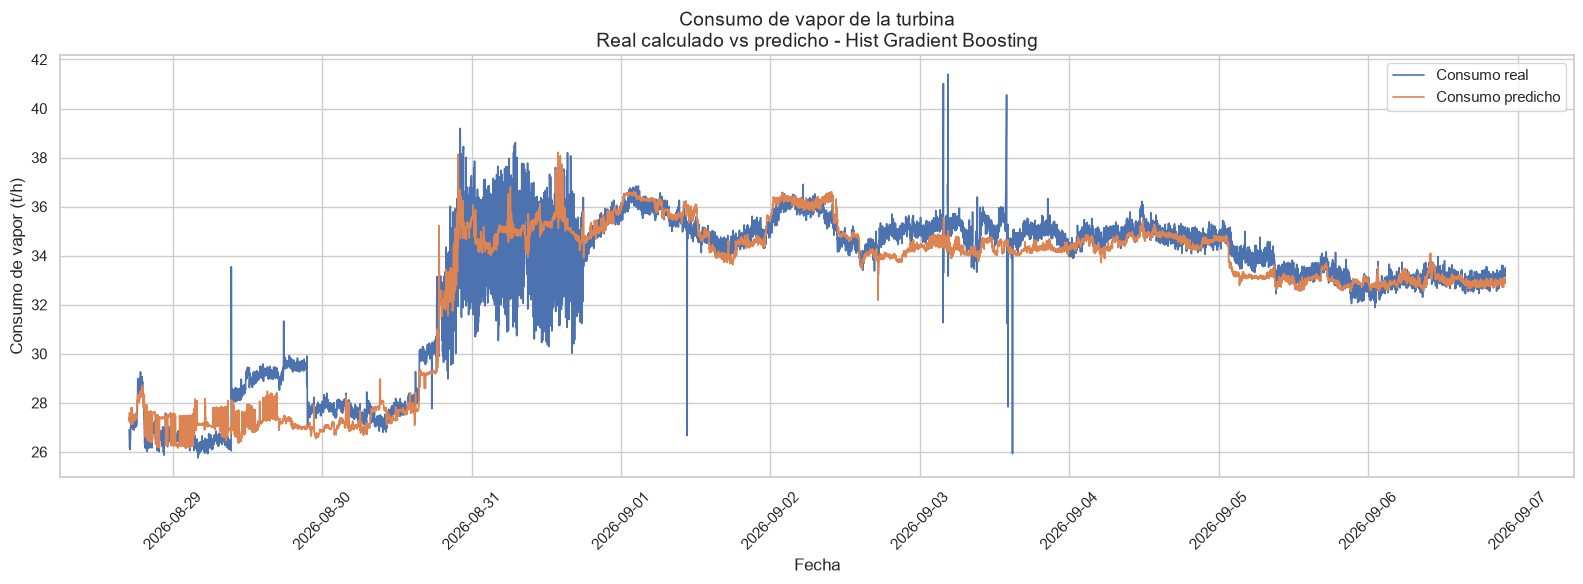

In [179]:
# ==========================================================
# GRÁFICA REAL VS PREDICHO
# HIST GRADIENT BOOSTING
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# ==========================================================
# 1. SELECCIONAR MEJOR MODELO
# ==========================================================

mejor_modelo = "Hist Gradient Boosting"

y_pred = predicciones_vapor_vacio[mejor_modelo]


# ==========================================================
# 2. RECUPERAR FECHAS DEL TEST
# ==========================================================

fechas_test = df_operacion2.loc[
    test_vapor_vacio.index,
    "FechaHora"
].values


# ==========================================================
# 3. CREAR DATAFRAME PARA LA GRÁFICA
# ==========================================================

df_grafica = pd.DataFrame({

    "FechaHora": fechas_test,

    "Consumo real": (
        y_test_vapor_vacio.values / 1000
    ),

    "Consumo predicho": (
        y_pred / 1000
    )
})


# ==========================================================
# 4. PASAR A FORMATO LARGO PARA SEABORN
# ==========================================================

df_grafica_long = df_grafica.melt(

    id_vars="FechaHora",

    value_vars=[
        "Consumo real",
        "Consumo predicho"
    ],

    var_name="Serie",

    value_name="Consumo de vapor (t/h)"
)


# ==========================================================
# 5. GRÁFICA CON SEABORN
# ==========================================================

sns.set_theme(style="whitegrid")

plt.figure(figsize=(16, 6))

sns.lineplot(
    data=df_grafica_long,
    x="FechaHora",
    y="Consumo de vapor (t/h)",
    hue="Serie",
    linewidth=1.2
)

plt.title(
    "Consumo de vapor de la turbina\n"
    "Real calculado vs predicho - Hist Gradient Boosting",
    fontsize=14
)

plt.xlabel("Fecha")
plt.ylabel("Consumo de vapor (t/h)")

plt.legend(
    title=""
)

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [180]:
variables_check = variables_vapor_vacio + [objetivo_vapor]

comparacion_rangos = pd.DataFrame({
    "TRAIN_min": train_vapor_vacio[variables_check].min(),
    "TRAIN_max": train_vapor_vacio[variables_check].max(),
    "TRAIN_mean": train_vapor_vacio[variables_check].mean(),
    "TEST_min": test_vapor_vacio[variables_check].min(),
    "TEST_max": test_vapor_vacio[variables_check].max(),
    "TEST_mean": test_vapor_vacio[variables_check].mean(),
})

print(comparacion_rangos)

                                         TRAIN_min      TRAIN_max  \
Presion_Condensador_kg_cm2A               0.016560       0.517781   
Flujo_Agua_Mar_m3_h                    1258.022705    5000.000000   
Temp_Entrada_Agua_Mar_C                  19.165905      25.770231   
Temp_Salida_Agua_Mar_C                   23.894316      36.047684   
Presion_Entrada_Agua_Mar_kg_cm2           4.550674       7.533339   
Flujo_Aire_Soplador_kg_h              59288.816406  139717.687500   
Presion_Descarga_Soplador_kg_cm2          1.031136       3.063797   
RPM_Turbina                            5232.600586    5340.659668   
Presion_Vapor_Entrada_Turbina_kg_cm2     37.359585      42.625153   
Temp_Vapor_Entrada_Turbina_C            320.131287     366.224060   
Presion_MS_Eyectores_kg_cm2               9.631863      12.489702   
Temp_MS_Eyectores_C                     226.253937     289.874817   
Flujo_Vapor_Turbina_kg_h              19323.958493   50296.576172   

                                 

In [181]:
# ============================================================
# OPTIMIZACIÓN Y COMPARACIÓN FINAL DE 4 MODELOS
# Machine Learning - Consumo de vapor de turbina
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ============================================================
# 1. VERIFICAR TAMAÑO DE TRAIN Y TEST
# ============================================================

print("=" * 70)
print("TAMAÑO DE LOS CONJUNTOS")
print("=" * 70)

print("X TRAIN:", X_train_vapor_vacio.shape)
print("y TRAIN:", y_train_vapor_vacio.shape)

print("X TEST :", X_test_vapor_vacio.shape)
print("y TEST :", y_test_vapor_vacio.shape)


# ============================================================
# 2. VALIDACIÓN TEMPORAL
# ============================================================

# Divide únicamente el TRAIN respetando el orden cronológico.
# El TEST final NO participa en la optimización.

tscv = TimeSeriesSplit(n_splits=4)

print("\n" + "=" * 70)
print("VALIDACIÓN TEMPORAL")
print("=" * 70)

for i, (train_idx, val_idx) in enumerate(
    tscv.split(X_train_vapor_vacio),
    start=1
):
    print(
        f"Fold {i}: "
        f"TRAIN = {len(train_idx):,} registros | "
        f"VALIDACIÓN = {len(val_idx):,} registros"
    )


# ============================================================
# 3. RANDOM FOREST
# ============================================================

print("\n" + "=" * 70)
print("OPTIMIZANDO RANDOM FOREST")
print("=" * 70)

modelo_rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

parametros_rf = {
    "n_estimators": [200, 300, 500],
    "max_depth": [8, 12, 16, 20, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10, 20],
    "max_features": ["sqrt", 0.7, 1.0]
}

busqueda_rf = RandomizedSearchCV(
    estimator=modelo_rf,
    param_distributions=parametros_rf,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

busqueda_rf.fit(
    X_train_vapor_vacio,
    y_train_vapor_vacio
)

mejor_rf = busqueda_rf.best_estimator_

print("\nMejores parámetros Random Forest:")
print(busqueda_rf.best_params_)

print(
    f"MAE promedio validación temporal: "
    f"{-busqueda_rf.best_score_/1000:.4f} t/h"
)


# ============================================================
# 4. EXTRA TREES
# ============================================================

print("\n" + "=" * 70)
print("OPTIMIZANDO EXTRA TREES")
print("=" * 70)

modelo_et = ExtraTreesRegressor(
    random_state=42,
    n_jobs=-1
)

parametros_et = {
    "n_estimators": [200, 300, 500],
    "max_depth": [8, 12, 16, 20, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10, 20],
    "max_features": ["sqrt", 0.7, 1.0]
}

busqueda_et = RandomizedSearchCV(
    estimator=modelo_et,
    param_distributions=parametros_et,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

busqueda_et.fit(
    X_train_vapor_vacio,
    y_train_vapor_vacio
)

mejor_et = busqueda_et.best_estimator_

print("\nMejores parámetros Extra Trees:")
print(busqueda_et.best_params_)

print(
    f"MAE promedio validación temporal: "
    f"{-busqueda_et.best_score_/1000:.4f} t/h"
)


# ============================================================
# 5. GRADIENT BOOSTING
# ============================================================

print("\n" + "=" * 70)
print("OPTIMIZANDO GRADIENT BOOSTING")
print("=" * 70)

modelo_gb = GradientBoostingRegressor(
    random_state=42
)

parametros_gb = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4, 5],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 5, 10, 20],
    "subsample": [0.7, 0.85, 1.0]
}

busqueda_gb = RandomizedSearchCV(
    estimator=modelo_gb,
    param_distributions=parametros_gb,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

busqueda_gb.fit(
    X_train_vapor_vacio,
    y_train_vapor_vacio
)

mejor_gb = busqueda_gb.best_estimator_

print("\nMejores parámetros Gradient Boosting:")
print(busqueda_gb.best_params_)

print(
    f"MAE promedio validación temporal: "
    f"{-busqueda_gb.best_score_/1000:.4f} t/h"
)


# ============================================================
# 6. HIST GRADIENT BOOSTING
# ============================================================

print("\n" + "=" * 70)
print("OPTIMIZANDO HIST GRADIENT BOOSTING")
print("=" * 70)

modelo_hgb = HistGradientBoostingRegressor(
    random_state=42
)

parametros_hgb = {
    "learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
    "max_iter": [100, 200, 300, 500],
    "max_depth": [5, 8, 10, 12, None],
    "min_samples_leaf": [10, 20, 30, 50],
    "l2_regularization": [0.0, 0.1, 1.0, 5.0]
}

busqueda_hgb = RandomizedSearchCV(
    estimator=modelo_hgb,
    param_distributions=parametros_hgb,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

busqueda_hgb.fit(
    X_train_vapor_vacio,
    y_train_vapor_vacio
)

mejor_hgb = busqueda_hgb.best_estimator_

print("\nMejores parámetros Hist Gradient Boosting:")
print(busqueda_hgb.best_params_)

print(
    f"MAE promedio validación temporal: "
    f"{-busqueda_hgb.best_score_/1000:.4f} t/h"
)


# ============================================================
# 7. GUARDAR LOS 4 MEJORES MODELOS
# ============================================================

modelos_finales = {
    "Random Forest": mejor_rf,
    "Extra Trees": mejor_et,
    "Gradient Boosting": mejor_gb,
    "Hist Gradient Boosting": mejor_hgb
}


# ============================================================
# 8. EVALUACIÓN FINAL SOBRE TEST
# ============================================================

print("\n" + "=" * 70)
print("EVALUACIÓN FINAL SOBRE TEST")
print("=" * 70)

resultados_finales = []
predicciones_finales = {}

for nombre, modelo in modelos_finales.items():

    y_pred = modelo.predict(
        X_test_vapor_vacio
    )

    predicciones_finales[nombre] = y_pred

    mae = mean_absolute_error(
        y_test_vapor_vacio,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test_vapor_vacio,
            y_pred
        )
    )

    r2 = r2_score(
        y_test_vapor_vacio,
        y_pred
    )

    resultados_finales.append({
        "Modelo": nombre,
        "MAE_kg_h": mae,
        "RMSE_kg_h": rmse,
        "MAE_t_h": mae / 1000,
        "RMSE_t_h": rmse / 1000,
        "R2": r2
    })


# ============================================================
# 9. TABLA FINAL
# ============================================================

resultados_finales = pd.DataFrame(
    resultados_finales
)

resultados_finales = (
    resultados_finales
    .sort_values(
        "R2",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("RESULTADOS FINALES")
print("=" * 70)

print(
    resultados_finales[[
        "Modelo",
        "MAE_t_h",
        "RMSE_t_h",
        "R2"
    ]].to_string(
        index=False
    )
)


# ============================================================
# 10. IDENTIFICAR MODELO GANADOR
# ============================================================

nombre_ganador = resultados_finales.loc[
    0,
    "Modelo"
]

modelo_ganador = modelos_finales[
    nombre_ganador
]

print("\n" + "=" * 70)
print("MODELO GANADOR")
print("=" * 70)

print(
    f"Mejor modelo según R² TEST: "
    f"{nombre_ganador}"
)

print("\nModelo:")
print(modelo_ganador)


# ============================================================
# 11. MOSTRAR LOS MEJORES HIPERPARÁMETROS DE TODOS
# ============================================================

print("\n" + "=" * 70)
print("MEJORES HIPERPARÁMETROS")
print("=" * 70)

print("\nRANDOM FOREST")
print(busqueda_rf.best_params_)

print("\nEXTRA TREES")
print(busqueda_et.best_params_)

print("\nGRADIENT BOOSTING")
print(busqueda_gb.best_params_)

print("\nHIST GRADIENT BOOSTING")
print(busqueda_hgb.best_params_)

TAMAÑO DE LOS CONJUNTOS
X TRAIN: (82145, 12)
y TRAIN: (82145,)
X TEST : (13261, 12)
y TEST : (13261,)

VALIDACIÓN TEMPORAL
Fold 1: TRAIN = 16,429 registros | VALIDACIÓN = 16,429 registros
Fold 2: TRAIN = 32,858 registros | VALIDACIÓN = 16,429 registros
Fold 3: TRAIN = 49,287 registros | VALIDACIÓN = 16,429 registros
Fold 4: TRAIN = 65,716 registros | VALIDACIÓN = 16,429 registros

OPTIMIZANDO RANDOM FOREST
Fitting 4 folds for each of 20 candidates, totalling 80 fits

Mejores parámetros Random Forest:
{'n_estimators': 500, 'min_samples_split': 20, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': None}
MAE promedio validación temporal: 0.6259 t/h

OPTIMIZANDO EXTRA TREES
Fitting 4 folds for each of 20 candidates, totalling 80 fits

Mejores parámetros Extra Trees:
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 20, 'max_features': 1.0, 'max_depth': 20}
MAE promedio validación temporal: 0.6297 t/h

OPTIMIZANDO GRADIENT BOOSTING
Fitting 4 folds for each of 20 ca

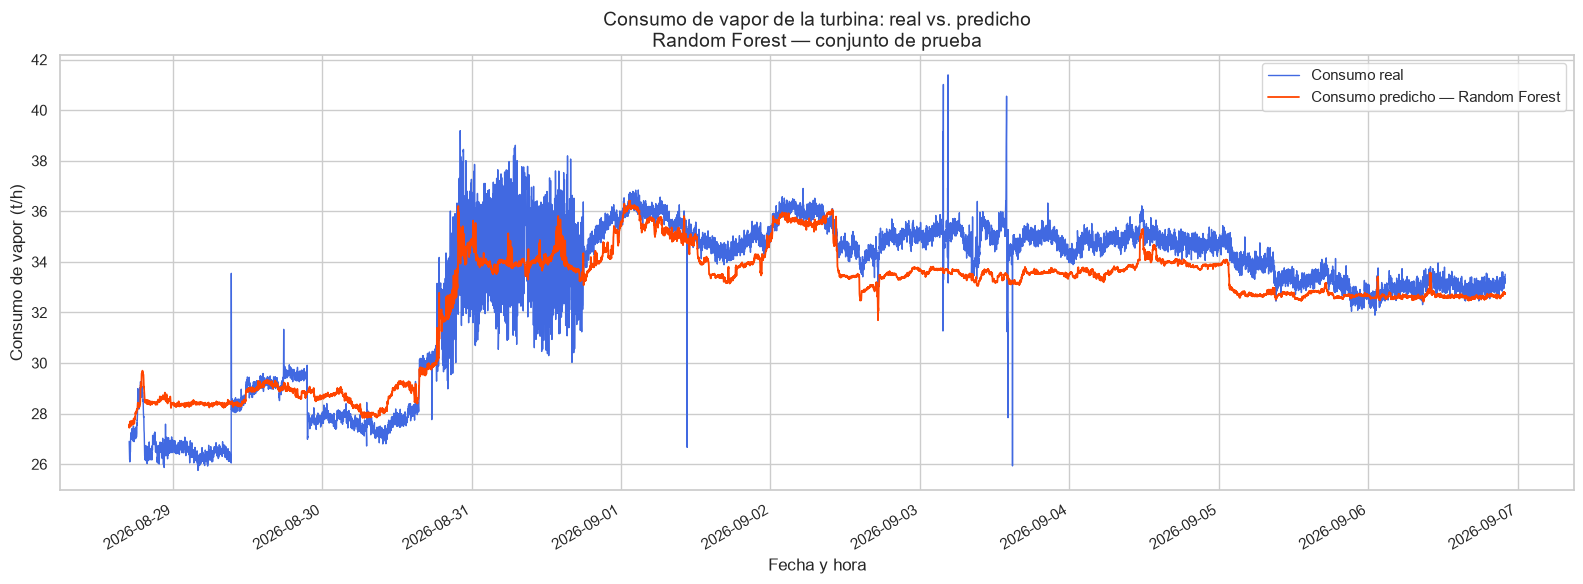

In [182]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor

# Random Forest con los mejores hiperparámetros encontrados
modelo_rf = RandomForestRegressor(
    n_estimators=500,
    min_samples_split=20,
    min_samples_leaf=1,
    max_features="sqrt",
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

modelo_rf.fit(X_train_vapor_vacio, y_train_vapor_vacio)

# Predicción sobre TEST
y_pred_rf = modelo_rf.predict(X_test_vapor_vacio)

# Alinear fechas y convertir de kg/h a t/h
df_grafica_rf = pd.DataFrame({
    "FechaHora": pd.to_datetime(
        df_operacion2.loc[X_test_vapor_vacio.index, "FechaHora"]
    ).to_numpy(),
    "Consumo real": np.asarray(y_test_vapor_vacio).ravel() / 1000,
    "Consumo predicho": np.asarray(y_pred_rf).ravel() / 1000
}).sort_values("FechaHora")

# Gráfica
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(16, 6))

sns.lineplot(
    data=df_grafica_rf,
    x="FechaHora",
    y="Consumo real",
    label="Consumo real",
    color="royalblue",
    linewidth=1,
    estimator=None,
    ax=ax
)

sns.lineplot(
    data=df_grafica_rf,
    x="FechaHora",
    y="Consumo predicho",
    label="Consumo predicho — Random Forest",
    color="orangered",
    linewidth=1.3,
    estimator=None,
    ax=ax
)

ax.set_title(
    "Consumo de vapor de la turbina: real vs. predicho\n"
    "Random Forest — conjunto de prueba",
    fontsize=14
)
ax.set_xlabel("Fecha y hora")
ax.set_ylabel("Consumo de vapor (t/h)")
ax.legend()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [183]:
import pandas as pd
import plotly.graph_objects as go

# ============================================================
# 1. GENERAR PREDICCIÓN DEL MODELO GANADOR SOBRE TODO EL TEST
# ============================================================

y_pred_hgb = modelo_ganador.predict(X_test_vapor_vacio)


# ============================================================
# 2. CREAR DATAFRAME DE RESULTADOS
# ============================================================

resultados_hgb = pd.DataFrame({
    "FechaHora": df_operacion2.loc[X_test_vapor_vacio.index, "FechaHora"].values,
    "Real_kg_h": y_test_vapor_vacio.values,
    "Predicho_kg_h": y_pred_hgb
})

# Convertir a t/h para que la gráfica sea más fácil de leer
resultados_hgb["Real_t_h"] = resultados_hgb["Real_kg_h"] / 1000
resultados_hgb["Predicho_t_h"] = resultados_hgb["Predicho_kg_h"] / 1000


# ============================================================
# 3. ORDENAR CRONOLÓGICAMENTE
# ============================================================

resultados_hgb = (
    resultados_hgb
    .sort_values("FechaHora")
    .reset_index(drop=True)
)


# ============================================================
# 4. CREAR GRÁFICA INTERACTIVA REAL VS PREDICHO
# ============================================================

fig = go.Figure()

# Valor real
fig.add_trace(
    go.Scatter(
        x=resultados_hgb["FechaHora"],
        y=resultados_hgb["Real_t_h"],
        mode="lines",
        name="Consumo real",
        hovertemplate=
        "<b>Fecha:</b> %{x}<br>" +
        "<b>Real:</b> %{y:.3f} t/h<extra></extra>"
    )
)

# Valor predicho
fig.add_trace(
    go.Scatter(
        x=resultados_hgb["FechaHora"],
        y=resultados_hgb["Predicho_t_h"],
        mode="lines",
        name="Consumo predicho - HGB",
        hovertemplate=
        "<b>Fecha:</b> %{x}<br>" +
        "<b>Predicho:</b> %{y:.3f} t/h<extra></extra>"
    )
)


# ============================================================
# 5. CONFIGURACIÓN DE LA GRÁFICA
# ============================================================

fig.update_layout(
    title=(
        "Consumo de vapor de la turbina: "
        "Real vs Predicho - Hist Gradient Boosting"
    ),

    xaxis_title="Fecha y hora",
    yaxis_title="Consumo de vapor (t/h)",

    hovermode="x unified",

    template="plotly_white",

    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="center",
        x=0.5
    ),

    height=600
)


# ============================================================
# 6. AGREGAR SELECTOR Y DESLIZADOR DE TIEMPO
# ============================================================

fig.update_xaxes(

    rangeslider_visible=True,

    rangeselector=dict(
        buttons=[
            dict(
                count=6,
                label="6 h",
                step="hour",
                stepmode="backward"
            ),

            dict(
                count=12,
                label="12 h",
                step="hour",
                stepmode="backward"
            ),

            dict(
                count=1,
                label="1 día",
                step="day",
                stepmode="backward"
            ),

            dict(
                count=3,
                label="3 días",
                step="day",
                stepmode="backward"
            ),

            dict(
                step="all",
                label="Todo"
            )
        ]
    )
)


# ============================================================
# 7. MOSTRAR
# ============================================================

fig.show()

In [184]:
import pandas as pd

# Recuperar las filas utilizadas en el entrenamiento.
revision_train = df_operacion.loc[
    train_vapor_vacio.index
].copy()

# Identificar consumos negativos.
registros_negativos = revision_train.loc[
    revision_train["Flujo_Vapor_Turbina_kg_h"] < 0
].copy()

columnas_revision = [
    "FechaHora",
    "Flujo_Vapor_Turbina_kg_h",
    "Vapor_MS_Importado_kg_h",
    "Vapor_MS_Exportado_kg_h",
    "Vapor_MS_Generado_kg_h",
    "Vapor_Compresor_Gases_kg_h",
    "Velocidad_P017A_rpm",
    "Velocidad_P017B_rpm",
    "Vapor_Bombas_Fondos_kg_h",
    "RPM_Turbina",
    "Flujo_Aire_Soplador_kg_h",
]

print(f"Registros utilizados en TRAIN: {len(revision_train):,}")
print(f"Registros con consumo negativo: {len(registros_negativos):,}")

if registros_negativos.empty:
    print("\nNo se encontraron consumos negativos en el TRAIN actual.")

else:
    detalle_negativos = registros_negativos[
        columnas_revision
    ].copy()

    detalle_negativos.insert(
        0, "Indice_df_operacion", detalle_negativos.index
    )

    print("\nREGISTROS IDENTIFICADOS:")
    print(detalle_negativos.to_string(index=False))

    # Mostrar el entorno del primer negativo en los datos originales,
    # incluidos los registros que no superaron el filtro operacional.
    fecha_evento = registros_negativos["FechaHora"].min()

    entorno_evento = df.loc[
        df["FechaHora"].between(
            fecha_evento - pd.Timedelta(minutes=5),
            fecha_evento + pd.Timedelta(minutes=5),
        ),
        columnas_revision,
    ].sort_values("FechaHora")

    print("\nENTORNO DEL PRIMER REGISTRO NEGATIVO: ±5 MINUTOS")
    print(entorno_evento.to_string(index=False))

Registros utilizados en TRAIN: 82,145
Registros con consumo negativo: 0

No se encontraron consumos negativos en el TRAIN actual.
